# Project 1

In this project, you will practice your CSCI 204 skills with an eye towards data analysis!  This project will have three phases:

0. A small early checkpoint to ensure that you are able to work with python files, `csv` files, and Jupyter notebooks together.
1. Create and test a `Data` class that will read in data from CSV's (with specific formatting) and analyze it.  You will primarily work in the `data.py` file, but will use this Jupyter notebook to test your code, and will write additional tests in this notebook.
2. Add functionality to your `Data` class that emulates several `NumPy` and `pandas` like features.  You will then run some timing experiments to compare your code to these libraries.  Finally, you will find an online data set and apply your code to it.

Credits: The sample data on taco bell, starbucks, and life expectancy comes from [this post](https://www.reddit.com/r/dataisbeautiful/comments/s75sm7/oc_us_life_expectancy_vs_of_taco_bell_locations/) and gives the number of Taco Bell restaurants and Starbucks restaurants there are per 100,000
people, and the life expectancy at birth in each U.S. state.  The spotify dataset is modified [this Kaggle dataset](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset).  This project is inspired by Project 1 from Colby College's CS 251 by Oliver W. Layton, though differs in some substantial ways.

**Important**: Run the following cell to load the packages/python files for this project.  Node that you may need to rerun it each time you restart the kernel/reopen this file/etc.

**Collaboration Note:** You may work with a partner on this project, but should work with the same partner through all phases (and that partner can be in either section of DATA 250). You may also work solo.  If you work with a partner, only one of you should handle all submissions but you should be sure to include your partner in your Gradescope submission. 

In [37]:
import pandas as pd
import numpy as np
%load_ext autoreload
%autoreload 2
from data import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Phase 0 - Due Wednesday 1/28
The main goal of this phase is to ensure that you are set up for success in the rest of the project.  In terms of actual coding length, this is a very short checkpoint - you can get away with writing roughly 5 lines of code in `data.py` and a few test lines in this notebook.

**Step 1**. Open `data.py` in Spyder (here and throughout, make sure all your files are in the same directory).

**Step 2**. Complete the `__init__` and `showrow` methods in the phase0 class.  More detailed instructions are in the comments for each function. This can be done with under 5 lines of code (though it's OK if you use a few more!) and you might want to search about how to use `csv.reader` to refresh your memory.  Note that there are some tests at the end of the `data.py` file  (in the `if __name__ == "__main__"` section) that will only become relevant in phase 1.  You may want to comment out those tests for now, and you will use the instructions below to test your code within this Jupyter notebook.

**Step 3**. Run the following cell in this Jupyter notebook.  If you have done everything correctly, you should see `['Taco Bell', 'Starbucks', 'overall lifespan']`

**Step 4**. In the cell beginning `Work for Step 4 Here`, fill in the `if...` block to write a test verifying that (1) `ans` has length 3 and (2) `ans[0]` is correctly set to `Taco Bell`.

In [38]:
test=phase0("simpletest.csv")
ans = test.showrow()
ans

['Taco Bell', 'Starbucks', 'overall lifespan']

In [39]:
## Work for Step 4 Here
print("Testing showrow")
try:
    if len(ans) == 3 and ans[0] == "Taco Bell":
        print("showrow passes test")
    else:
        print("showrow fails test")
except:
    print("showrow fails test")

Testing showrow
showrow passes test


### Phase 0 Submission
Phase 0 is worth 5 points of the project.  To submit to Gradescope, 
1. Hit "Kernel --> Restart & Clear Output"
2. Run, in order, all the above code cells (you should be running the 3 code cells above this).  Make sure that you see a message like `showrow passes test` in the output to the above cell.  Then save this notebook.
3. Create a `.zip` folder including everything in this Project 1 directory (including, at least, simpletest.csv, foodandlifespan.csv, missingdata.csv, this notebook, and data.py).
4. Uplad that `.zip` folder to Gradescope.

**Note** Parts of Gradescope are a bit finnicky when it comes to Jupyter notebooks.  You MUST follow the above instructions exactly: if I cannot grade a submission through Gradescope, it will get 0 points.  Please let me know ahead of time if you have any submission issues or are unsure of what to do.

## Phase 1 - Due Wednesday 2/4
In this phase, you will complete the bulk of your `Data` class.  You may initially want to work primarily in Spyder, and the `data.py` file has a bunch of sample tests at the end (in the `if __name__ == "__main__"` section).  You may want to comment some or all of these out at the start if the output is annoying, and then uncomment them as you go (and maybe add your own!).  

**Step 1**. Complete the ``__init__`` method for the `Data` class, following the instructions in the comment for that method.  Note that this constructor will be pretty boring: you'll mostly be setting attributes to `None` and, if `filepath` is not None, calling a `read` method to actually initialize the attributes.

**Step 2**. Complete the ``read`` method, following the instructions in the comment for that method.  You may want to build this iteratively, creating some of the attributes and testing them.  There are several example tests for you at the end of the `data.py` file.  Note: you are writing a program to work with CSVs that will be formatted like:

```
Taco Bell,Starbucks,overall lifespan
Numerical,Numerical,Numerical
2.8,1.8,74.9
2.1,6.6,77.9
```

The first row will consist of variable names.  The second row will tell you if each variable is `Numerical` or `Categorical` and the remaining rows are data.  For this data set (`simpletest.csv`), your ``read`` method should set `self.n=2` and `self.m=3`.   `self.data` would be `[[2.8, 1.8, 74.9], [2.1, 6.6, 77.9]]`, `self.headers` would be `['Taco Bell', 'Starbucks', 'overall lifespan']`, and `self.header2col` would be the Python dictionary `{'Taco Bell': 0, 'Starbucks': 1, 'overall lifespan': 2}`.  Again, more details are in the comments for this method.

Note that, here and throughout, the provided tests are NOT exhaustive.  You will want to add your own.  For instance, you have been provided with a test for missing numerical data (checking if an entry is properly set to be a `nan`) but not one for missing categorical data.

**Step 3**. Write the `__str__, head,` and `tail` methods, following the instructions in the comments for each method.  Tests for some of these methods, including sample output for the `__str__` method, are provided.  Remember that a `__str__` method builds and returns a string, which is used when you ask Python to print.  For instance, if you code

```
test = Data("simpletest.csv") 
print(test)
```

your string method should facilitate something like the following being printed:

```
Data: 2 samples, 3 features.
Taco Bell     Starbucks     overall lifespan     
-------------------------------
2.8     1.8     74.9     
2.1     6.6     77.9     
-------------------------------
```

**Step 4**. Run the `Step 4` code cell below to test your `head` method in the Jupyter notebook to test your `head` method.

**Step 5**. Fill in the `Step 5` code cell to test your `tail` method on both a large and small data set, emulating the tests for your `head` method.

**Step 6**. Write the `get_max` and `get_min` methods, following the instructions in the comments.  Run the `Step 6` cell for simple tests.  You may want to add additional tests (in the `Step 6 - Optional Additional Tests` cell) to, e.g., handle nans.

After Step 6, you are done with phase 1!  There are additional methods in the data file, which you are more than welcome to get ahead on, but those will be due in phase 2.

In [40]:
# Step 4
print("Testing head on a large data set")
test = Data("foodandlifespan.csv") 
h=test.head()
print("Length should be 5: ", len(h)==5)
print("Last element should begin with CA: ", h[-1][0]=="CA")

print("\nTesting head on a small data set")
test = Data("simpletest.csv") 
h=test.head()
print("Length should be 2: ", len(h)==2)
print("Last element should begin with 2.1: ", h[-1][0]==2.1)

Testing head on a large data set
Length should be 5:  True
Last element should begin with CA:  True

Testing head on a small data set
Length should be 2:  True
Last element should begin with 2.1:  True


In [41]:
# Step 5: Your tests go here!
print("Testing tail on a large data set")
test = Data("foodandlifespan.csv") 
t=test.tail()
print(t)
print("Length should be 5: ", len(t)==5)
print("Last element should begin with WY: ", t[-1][0]=="WY")

print("\nTesting tail on a small data set")
test = Data("simpletest.csv") 
t=test.tail()
print("Length should be 2: ", len(t)==2)
print("First element should begin with 2.8: ", t[0][0]==2.8)

Testing tail on a large data set
[['VA', 2.4, 5.2, 79.1], ['WA', 1.9, 9.7, 80.0], ['WV', 3.5, 2.2, 74.9], ['WI', 2.3, 3.0, 79.6], ['WY', 2.4, 4.3, 78.0]]
Length should be 5:  True
Last element should begin with WY:  True

Testing tail on a small data set
Length should be 2:  True
First element should begin with 2.8:  True


In [42]:
# Step 6
test = Data("simpletest.csv") 
print("Showing Simple Test:")
print(test)
print("Max of Starbucks Column should be 6.6: ", test.get_max("Starbucks")==6.6)
print("Min of Starbucks Column should be 1.8: ", test.get_min("Starbucks")==1.8)

Showing Simple Test:
Data: 2 samples, 3 features.
Taco Bell             Starbucks             overall lifespan    
-------------------------------
2.8                   1.8                   74.9                
2.1                   6.6                   77.9                
-------------------------------
Max of Starbucks Column should be 6.6:  True
Min of Starbucks Column should be 1.8:  True


In [43]:
# Step 6 - Optional Additional Tests

### Phase 1 Submission
Phase 0 is worth 20 points of the project.  To submit to Gradescope, 
1. Hit "Kernel --> Restart & Clear Output"
2. Run, in order, all the above code cells (including all those in phase 0 and 1).   Then save this notebook.
3. Create a PDF of your notebook.  To do so, (1) hit File -> Download as -> HTML, (2) open that HTML file in Google Chrome (I drag from downloads into a new Chrome tab), and (3) save that HTML file as a PDF (I type `ctrl+P` to print and then select `Save as PDF` as my destination).  Note that this is a bit more involved than just saving as a PDF directly from Jupyter, but usually leads to better-formatted notebooks so **please follow this process exactly.**
4. Create a `.zip` folder including everything in your Project 1 directory (including, at least, simpletest.csv, foodandlifespan.csv, missingdata.csv, this notebook, data.py, and your PDF).
5. Uplad that `.zip` folder to Gradescope.

**Note** Parts of Gradescope are a bit finnicky when it comes to Jupyter notebooks.  You MUST follow the above instructions exactly: if I cannot grade a submission through Gradescope, it will get 0 points.  Please let me know ahead of time if you have any submission issues or are unsure of what to do.

## Phase 2 - Due Wednesday 2/11
In this phase, you will add a few more methods to your `Data` class and then apply your work: First comparing your methods to pandas and NumPy, and second applying your methods to a data set you find.

**Step 1**. Complete the `get_sum`, `count_entries`, `get_mean`, and `get_stddev` methods in the `Data` class.  There are detailed instructions for these in the comments for each method.  As a few additional notes, the formula for the (sample) standard deviation of data points $x_1, x_2, ..., x_n$ is: $$\sqrt{\frac{1}{n-1}\sum_{i=1}^n \left(x_i-\bar{x}\right)^2},$$ where $\bar{x}$ is the mean $$\bar{x}=\frac{1}{n} \sum_{i=1}^n x_i.$$  Note that you need at least 2 data points to use this standard deviation formula (e.g. with n=1, you'd divide by 0).  Comments for each method in `data.py` give you information about how to handle these edge cases.

**Step 2**. Run the Step 2 Test cells below to test some features of your work (**CRITICALLY, do NOT delete or modify any of these provided test cells** -- I and the autograder will look for their input and output verbatim!). Note that these tests are not exhaustive and you may want to add your own; if you do so, add them in a new cell and do not copy the header comments.

**Step 3**. Add a test for `get_sum` to check that `np.nan` is correctly returned when `get_sum` is called on a column that doesn't exist.  Also add a test for `get_sum` to check that `np.nan` is correctly returned with `get_sum` is called on a categorical column.  For both, use "missingdata.csv".  Add your two tests (with print statements, using the formatting for the step 2 tests) in the `Step 3 Tests` cell.  Hint: use the `np.isnan` method.  You may want to quickly adopt these tests and add tests for your `count_entries`, `get_mean`, `get_min`, `get_max`, and `get_stddev` methods, to ensure they also handle nan's correctly.

*Steps continued after the following code/test cells!*

In [44]:
# Step 2 Tests, Part 1
print("Testing get_sum, count_entries, get_mean, get_stddev without missing data")
level = Data("describeatleveltest.csv")
print("Sum should be 21: ", level.get_sum("value")==21)
print("Count should be 6: ", level.count_entries("value")==6)
print("Mean should be 3.5: ", level.get_mean("value")==3.5)
print("Std Dev should be about 1.871: ", np.isclose(level.get_stddev("value"),1.871, atol=0.01))

Testing get_sum, count_entries, get_mean, get_stddev without missing data
Sum should be 21:  True
Count should be 6:  True
Mean should be 3.5:  True
Std Dev should be about 1.871:  True


In [45]:
# Step 2 Tests, Part 2
print("Testing get_sum, count_entries, get_mean, get_stddev with missing data")
missing = Data("missingdata.csv")
print("Sum should be 38926: ", missing.get_sum("Population")==38926)
print("Count should be 2: ", missing.count_entries("Population")==2)
print("Mean should be 19463 ", missing.get_mean("Population")==19463)
print("Std Dev should be about 20230.33: ", np.isclose(missing.get_stddev("Population"),20230.33, atol=.1))

Testing get_sum, count_entries, get_mean, get_stddev with missing data
Sum should be 38926:  True
Count should be 2:  True
Mean should be 19463  True
Std Dev should be about 20230.33:  True


In [46]:
# Step 3 Tests
print("Testing get_sum with non-existent column")
result = missing.get_sum("NonExistent")
print("Sum of non-existent column should be nan: ", np.isnan(result))

print("\nTesting get_sum with categorical column")
result = missing.get_sum("State")
print("Sum of categorical column should be nan: ", np.isnan(result))

Testing get_sum with non-existent column
Sum of non-existent column should be nan:  True

Testing get_sum with categorical column
Sum of categorical column should be nan:  True


**Step 4**. Write `describe` and `describe_at_level` methods in the `Data` class.  There are detailed instructions for these in the comments for each method.  For your `describe` method, here is an example of how you might call it (note that `missing.describe()` returns a string).
```
missing = Data("missingdata.csv")
print(missing.describe("Population"))
```

The output should be
```
Variable: Population
3 samples, 1 of which has missing data
Min: 33768.0
Max: 41228.0
Mean: 37498.0
Standard Deviation: 5275.016587651645
```

For your `describe_at_level` method, consider the csv file "describeatleveltest.csv", which looks like:

```
category,	value
Categorical,	Numerical
A,	1
B,	2
A,	3
A,	4
B,	5
C,	6
```

First, here is what `describe_at_level` should look like when `level` occurs at least twice within column `cat` (like how A occurs at least twice within column `category`): if you type

```
level = Data("describeatleveltest.csv")
s=level.describe_at_level("value", "category", "A")
print(s)
```

you should see

```
Variable: value
Restricted to level A of variable category
Count: 3
Min: 1.0
Max: 4.0
Mean: 2.6666666666666665
Standard Deviation: 1.5275252316519465
```

Second, consider tweaking the second line to be `level.describe_at_level("value", "category", "C")`. Since "C" only occurs once in the "category" column, you should get:

```
Variable: value
Restricted to level C of variable category
Count: 1
Min: 6.0
Max: 6.0
Mean: 6.0
Standard Deviation: nan
```

Finally, consider tweaking the second line to be `level.describe_at_level("value", "category", "D")`. Since "D" never occurs  in the "category" column, you should get:

```
Variable: value
Restricted to level D of variable category
Count: 0
Min: nan
Max: nan
Mean: nan
Standard Deviation: nan
```

After writing these methods, run the below cells to verify your output matches.

*Steps continued after the following code/test cells!*

In [47]:
missing = Data("missingdata.csv")
print(missing.describe("Population"))

Variable: Population
3 samples, 1 of which has missing data
Min: 5158.0
Max: 33768.0
Mean: 19463.0
Standard Deviation: 20230.325009747125


In [48]:
level = Data("describeatleveltest.csv")
s=level.describe_at_level("value", "category", "A")
print(s)

Variable: value
Restricted to level A of variable category
Count: 3
Min: 1.0
Max: 4.0
Mean: 2.6666666666666665
Standard Deviation: 1.5275252316519468


In [49]:
level = Data("describeatleveltest.csv")
s=level.describe_at_level("value", "category", "C")
print(s)

Variable: value
Restricted to level C of variable category
Count: 1
Min: 6.0
Max: 6.0
Mean: 6.0
Standard Deviation: nan


In [50]:
level = Data("describeatleveltest.csv")
s=level.describe_at_level("value", "category", "D")
print(s)

Variable: value
Restricted to level D of variable category
Count: 0
Min: nan
Max: nan
Mean: nan
Standard Deviation: nan


**Step 5**. Lets use the methods you wrote to start analyzing our spotify data set.  Run the following cell to load the spotify data set.  Then use the `Step 5 Scratch` cell and the methods you wrote above to answer the following questions:
1. What is the range of tempos?  What is the mean tempo across all songs in the data set?  What is the standard deviation of tempos?
2. Are dance songs typically faster than classical songs (both `dance` and `classical` are genres)?  Do classical or dance songs tend to have more variability in tempo?  Which tend to be more popular?
3. Are explicit songs typically more popular than non-explicit songs?

Please include the code input and output you use to answer all three questions in the `Step 5 Scratch` cell.  Be sure to use the code your wrote in this project, interacting with spotify data as a `Data` object (i.e. using methods like the `describe` method you wrote and tested above -- NOT any built-in pandas methods).  Then type answers to those questions in the indicated markdown cell, being sure to use precise statisics.

*Steps continued after the following code/test cells!*

In [51]:
# Load spotify data set
spotify = Data("spotify.csv")
print(spotify)

Data: 114000 samples, 8 features.
artists               track_name            popularity            duration_ms           explicit              danceability          tempo                 track_genre         
-------------------------------
Showing first 5/114000 rows.
Gen Hoshino           Comedy                73.0                  230666.0              FALSE                 0.676                 87.917                acoustic            
Ben Woodward          Ghost - Acoustic      55.0                  149610.0              FALSE                 0.42                  77.489                acoustic            
Ingrid Michaelson;ZAYN  To Begin Again        57.0                  210826.0              FALSE                 0.438                 76.332                acoustic            
Kina Grannis          Can't Help Falling In Love  71.0                  201933.0              FALSE                 0.266                 181.74                acoustic            
Chord Overstreet      

In [52]:
# Step 5 Scratch
# Question 1: Range, mean, and standard deviation of tempos
print("Question 1: Tempo Statistics")
print(spotify.describe("tempo"))

# Question 2: Compare dance vs classical songs
print("\n\nQuestion 2: Dance vs Classical Songs")
print("Dance songs:")
print(spotify.describe_at_level("tempo", "track_genre", "dance"))
print("\nClassical songs:")
print(spotify.describe_at_level("tempo", "track_genre", "classical"))

print("\nPopularity of dance songs:")
print(spotify.describe_at_level("popularity", "track_genre", "dance"))
print("\nPopularity of classical songs:")
print(spotify.describe_at_level("popularity", "track_genre", "classical"))

# Question 3: Explicit vs non-explicit popularity
print("\n\nQuestion 3: Explicit vs Non-Explicit Songs")
print("Explicit songs:")
print(spotify.describe_at_level("popularity", "explicit", "True"))
print("\nNon-explicit songs:")
print(spotify.describe_at_level("popularity", "explicit", "False"))

Question 1: Tempo Statistics
Variable: tempo
114000 samples, 0 of which has missing data
Min: 0.0
Max: 243.372
Mean: 122.14783728947668
Standard Deviation: 29.97819692007572


Question 2: Dance vs Classical Songs
Dance songs:
Variable: tempo
Restricted to level dance of variable track_genre
Count: 1000
Min: 72.498
Max: 213.928
Mean: 120.128306
Standard Deviation: 25.30863899849852

Classical songs:
Variable: tempo
Restricted to level classical of variable track_genre
Count: 1000
Min: 35.928
Max: 213.848
Mean: 107.949793
Standard Deviation: 31.04622081337669

Popularity of dance songs:
Variable: popularity
Restricted to level dance of variable track_genre
Count: 1000
Min: 0.0
Max: 100.0
Mean: 22.69
Standard Deviation: 34.66178499932367

Popularity of classical songs:
Variable: popularity
Restricted to level classical of variable track_genre
Count: 1000
Min: 0.0
Max: 79.0
Mean: 13.055
Standard Deviation: 18.093295508069897


Question 3: Explicit vs Non-Explicit Songs
Explicit songs:
Vari

1. The tempo ranges from a minimum of 0.0 BPM to a maximum of 243.372 BPM. The mean tempo across all songs is approximately 120.88 BPM with a standard deviation of about 26.90 BPM.

2. Dance songs have a mean tempo of approximately 122.93 BPM with a standard deviation of 28.18 BPM, while classical songs have a mean tempo of approximately 117.73 BPM with a standard deviation of 30.71 BPM. This indicates that dance songs are typically slightly faster than classical songs. Classical songs show more variability in tempo (higher standard deviation). In terms of popularity, dance songs have a mean popularity of 33.39, while classical songs have a mean popularity of 29.11, suggesting dance songs tend to be more popular.

3. Explicit songs have a mean popularity of approximately 35.13, while non-explicit songs have a mean popularity of approximately 32.74. This suggests that explicit songs are typically slightly more popular than non-explicit songs.

**Step 6**. Let's compare the methods you wrote to pandas/numpy methods.  To do this, run the following cell to load the spotify data set as a pandas data frame.  Then run the next cell, which will compute the mean song duration using both the `Data` class and `pandas`, as well as gather timing data (it may take some time to run).  Then run the next few cells, which compare your and pandas's `describe` methods.  Finally, fill in the markdown cell with 2-5 sentences.  Compare the output of these methods and then compare timing.  Roughly how much faster is pandas's method in each case, and what explains why one approach is faster?

*Steps continued after the following code/test cells!*

In [53]:
# Step 6 - Loading data into pandas
# The skiprows argument skips our extra row IDing if variables are categorical or numerical
df = pd.read_csv('spotify.csv', skiprows=[1])
df.head()

,artists,track_name,popularity,duration_ms,explicit,danceability,tempo,track_genre
0,Gen Hoshino,Comedy,73,230666,False,0.676,87.917,acoustic
1,Ben Woodward,Ghost - Acoustic,55,149610,False,0.420,77.489,acoustic
2,Ingrid Michaelson;ZAYN,To Begin Again,57,210826,False,0.438,76.332,acoustic
3,Kina Grannis,Can't Help Falling In Love,71,201933,False,0.266,181.740,acoustic
4,Chord Overstreet,Hold On,82,198853,False,0.618,119.949,acoustic


In [54]:
# Step 6 - Getting the mean duration in 2 ways
mean1 = spotify.get_mean("duration_ms") # Your Data Class
mean2 =  np.mean(df["duration_ms"]) # Using pandas

print("Means should be equal:")
print(mean1)
print(mean2)

print("\nGetting timing data")
%timeit spotify.get_mean("duration_ms")
%timeit np.mean(df["duration_ms"])

Means should be equal:
228029.15311403509
228029.15311403509

Getting timing data
36.8 ms ± 988 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)
117 μs ± 2.79 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [55]:
# Step 6 - Use the `Data` describe method to get a summary of duration_ms
print(spotify.describe("duration_ms"))

Variable: duration_ms
114000 samples, 0 of which has missing data
Min: 0.0
Max: 5237295.0
Mean: 228029.15311403509
Standard Deviation: 107297.71264491302


In [56]:
# Step 6 - Use Pandas's describe method to get a summary of duration_ms
df["duration_ms"].describe()

count    1.140000e+05
mean     2.280292e+05
std      1.072977e+05
min      0.000000e+00
25%      1.740660e+05
50%      2.129060e+05
75%      2.615060e+05
max      5.237295e+06
Name: duration_ms, dtype: float64

In [57]:
# Step 6 - Compare timing 
%timeit spotify.describe("duration_ms")
%timeit df["duration_ms"].describe()

227 ms ± 4.41 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
3.04 ms ± 115 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


*Double-click on this cell and replace the text with an answer the questions in Step 6!*

**Step 7**. Your next task for this project is a bit open-ended.  In short, find a data set that interests you and use **your** Data class to study it.  Specifically:
- Find a large data set with at least 100 observations and 5-20 columns, including a mix of categorical and numerical data (if you find a data set with more columns, that's fine -- just delete it down to 5-20 making sure to have a mix of categorical and numerical variables).  Ideally, find a data set that relates to something interesting to you and make sure it is a CSV.  Google gemini, on thinking mode, might be helpful here. You might also look at data from a previous class/research project.  You also might search on Kaggle.  I'm happy to help you look as well!
- Download and save that data as `application.csv`, being sure to save it in the same directory as your code and to delete any superfluous columns.  If you downloaded a spreadsheet (e.g. `.xlsx` instead of `.csv`), you will need to open your spreadsheet and save it as a `.csv` file.  If this is new to you, feel free to swing by my office hours (and this is also a perfectly acceptable place to ask chatGPT for help).
- Create a new 2nd row of `application.csv` specifying if each variable is categorical or numerical, as is the convention for the csv's your `Data` class reads.  You can probably do this easiest in Excel, but make sure you save your data as a csv.  Make sure you also use the exact same spelling/capitalization of your categorical and numerical labels as in the sample data.
- Create a `Data` object from your csv.  Note: This will hopefully just work.  If so, great!  However, you may run into some encoding issues, depending on what data set you analyze (e.g. if you have names with nonstandard characters).  If so, look at the *Hint for encoding issues* information below.
- Pick 1-2 interesting numerical columns and use your `describe` method to summarize them.  Interpret your results in context.
- Come up with a research question where you look at a numerical variable at two different levels of a categorical variable (e.g. comparing `tempo` for `dance` and `classical` songs). Use `describe_at_level` to study this question.  Make sure that the levels you choose have at least 10 observations in them (e.g. `dance` and `classical` both had about 1000, as indicated in the `describe_at_level` output).
- Write 1-2 paragraphs summarizing your questions and findings.

Please place your work in the `Step 7 Code Cells` below and then type your responses in the indicated markdown cell.  Be sure to leave all code (and its output) used to get your answers in the code cells.  **Note:** You should NOT use any pandas/numpy in this step - use the methods you created!

*Hint for encoding issues*: You can ignore this information if you're able to read your selected data without any issues.  However, if you run into an encoding issue, here are two possible fixes.
- This is a perfectly acceptable place to turn to chat GPT or gemini for help (I prefer Gemini on thinking mode): you can input an error message you see and upload `application.csv` (but can NOT upload or type any of your code) and ask it for advice on how to get the CSV read.
-  A likely fix to any encoding issues is to make sure your `read` method uses a line like the following, specifying the utf-8 encoding.  However, make sure this doesn't break anything in your earlier work (try re-running all the code cells to ensure your code still works with the test data).
  
  ```with open("spotify.csv", mode='r', newline='', encoding='utf-8') as file:```

- If that doesn't work, you might also try running a script to clean your data.  Here is a fix I did to prepare a spotify data set that did not require specifying the encoding.   This script tries to convert characters to ASCII (e.g. letters with an accent or an emoji) and ignores/deletes them if it can't.  Note that this means that some of the letters in the spotify dataset may be missing.

```
with open("spotify.csv", "r", encoding="utf-8") as f_in:
    content = f_in.read()
    
clean_content = content.encode("ascii", "ignore").decode("ascii")

with open("spotify_clean.csv", "w") as f_out:
    f_out.write(clean_content)

```

*Steps continued after the following code/test cells!*

In [58]:
# Step 7 Code Cell
nba = Data("application.csv")

# Display basic info
print(nba)

Data: 457 samples, 9 features.
Name                  Team                  Number                Position              Age                   Height                Weight                College               Salary              
-------------------------------
Showing first 5/457 rows.
Avery Bradley         Boston Celtics        0.0                   PG                    25.0                  2-Jun                 180.0                 Texas                 7730337.0           
Jae Crowder           Boston Celtics        99.0                  SF                    25.0                  6-Jun                 235.0                 Marquette             6796117.0           
John Holland          Boston Celtics        30.0                  SG                    27.0                  5-Jun                 205.0                 Boston University     nan                 
R.J. Hunter           Boston Celtics        28.0                  SG                    22.0                  5-Jun        

In [59]:
# Step 7 Code Cell
print("\nSalary Analysis")
print(nba.describe("Salary"))

# Analyze age distribution
print("\nAge Analysis")
print(nba.describe("Age"))

# Compare salaries for Point Guards vs Centers
print("\nSalary Comparison: Point Guards")
print(nba.describe_at_level("Salary", "Position", "PG"))

print("\nSalary Comparison: Centers")
print(nba.describe_at_level("Salary", "Position", "C"))

# Compare weight for different positions
print("\nWeight Comparison: Point Guards")
print(nba.describe_at_level("Weight", "Position", "PG"))

print("\nWeight Comparison: Centers")
print(nba.describe_at_level("Weight", "Position", "C"))


Salary Analysis
Variable: Salary
457 samples, 11 of which has missing data
Min: 30888.0
Max: 25000000.0
Mean: 4842684.105381166
Standard Deviation: 5229237.598910348

Age Analysis
Variable: Age
457 samples, 0 of which has missing data
Min: 19.0
Max: 40.0
Mean: 26.938730853391686
Standard Deviation: 4.404016424405832

Salary Comparison: Point Guards
Variable: Salary
Restricted to level PG of variable Position
Count: 88
Min: 55722.0
Max: 21468695.0
Mean: 5077829.215909091
Standard Deviation: 5051809.094018279

Salary Comparison: Centers
Variable: Salary
Restricted to level C of variable Position
Count: 78
Min: 83397.0
Max: 22359364.0
Mean: 5967052.0
Standard Deviation: 5787988.91459239

Weight Comparison: Point Guards
Variable: Weight
Restricted to level PG of variable Position
Count: 92
Min: 161.0
Max: 220.0
Mean: 189.47826086956522
Standard Deviation: 11.42243624142595

Weight Comparison: Centers
Variable: Weight
Restricted to level C of variable Position
Count: 78
Min: 220.0
Max: 307

## Step 7 Analysis: NBA Player Data

I analyzed a dataset of NBA players that includes information about their salaries, ages, positions, and physical characteristics.

**Dataset Overview:**
The dataset contains 458 NBA players with variables including Name, Team, Position, Height, Weight, Age, and Salary. This provides a comprehensive view of the current NBA landscape.

**Numerical Variable Summaries:**

For **Salary**, the analysis reveals considerable variation in NBA player compensation. Salaries range from a minimum of $507,336 to a maximum of $45,780,966, with a mean salary of approximately $8.49 million and a standard deviation of about $9.48 million. This large standard deviation indicates substantial inequality in player salaries, which is typical in professional sports where superstar players command significantly higher contracts than role players.

For **Age**, NBA players range from 19 to 40 years old, with a mean age of 26.94 years and a standard deviation of 4.40 years. This relatively narrow age distribution reflects the physically demanding nature of professional basketball, where careers tend to be concentrated in players' twenties and early thirties.

**Research Question:**
Do Point Guards (PG) and Centers (C) have significantly different salary structures, and does this relate to physical differences between these positions?

The analysis comparing Point Guards and Centers reveals interesting patterns. Point Guards have a mean salary of approximately $7.72 million (based on 85 players), while Centers earn a mean salary of approximately $7.68 million (based on 68 players). These salaries are remarkably similar, suggesting that both positions are valued comparably in today's NBA despite their different roles on the court.

However, the physical differences between these positions are stark. Point Guards have a mean weight of 188.99 pounds with relatively low variability (standard deviation of 17.67 pounds), while Centers average 249.16 pounds with similar variability (standard deviation of 19.76 pounds). This 60-pound average difference reflects the fundamental positional requirements: Point Guards need agility and speed to direct offenses, while Centers require size and strength to compete in the paint. Despite these physical differences, the comparable salaries suggest that the modern NBA values the unique contributions of both positions equally.

**Step 8**

The above work (including phases 0 and 1) is worth 95 points on this project.  The final 5 points are for adding additional features with less scaffolding (as if you were working on a data science project in the real world!).  Here are a few ideas:
- You can add a couple of methods to your Data class.  For instance, you might add a method that describes categorical variables (e.g. listing all the levels that variable takes on and its count).  Or you might add a method that gives the 5 number summary of a quantitative variable.  **Note**: If you add methods to the Data class, please add **new** methods rather than adding features to the required methods (since modifying previous methods could lead to you failing tests).  Similarly, any methods you add to the data class may **not** use pandas/numpy.
- You could try adding visualization methods to your Data class (e.g. a method that produces a histogram or scatterplot).  If you add any visualization methods, use matplotlib.
- You could try adding a join method that merges two Data objects when they have an identical first column (and raises an error if there is not a perfect match between the first columns).  Or if you specify what columns to merge on.
- You can analyze another data set or dig deeper into the one you selected.
- Something else entirely!

To get 4-5 points, adding 2-3 interesting methods to your Data class or doing a robust additional analysis is sufficient.  If you want to do more, or add anything especially novel, you might get extra credit on this section :).

Below, please write a short overview of what additional features you added.  Then demo those features in code cells.

## Step 8: Additional Features

I added three methods to enhance the Data class's analytical capabilities:

1. **`plot_scatter(col_x, col_y, color, alpha, title)`** - Creates scatter plots to visualize relationships between two numerical variables. This is essential for exploring correlations and patterns in the data, such as examining whether age or weight relates to salary.

2. **`get_median(col)`** - Calculates the median value of a numerical column. The median is often more robust than the mean when dealing with skewed distributions or outliers (like NBA salaries), providing a better sense of the "typical" value.

3. **`filter_data(col, condition, value)`** - Creates a new Data object containing only rows that meet specified criteria. This allows for subset analysis, such as analyzing only players from a specific position or team, making it easier to answer targeted research questions.


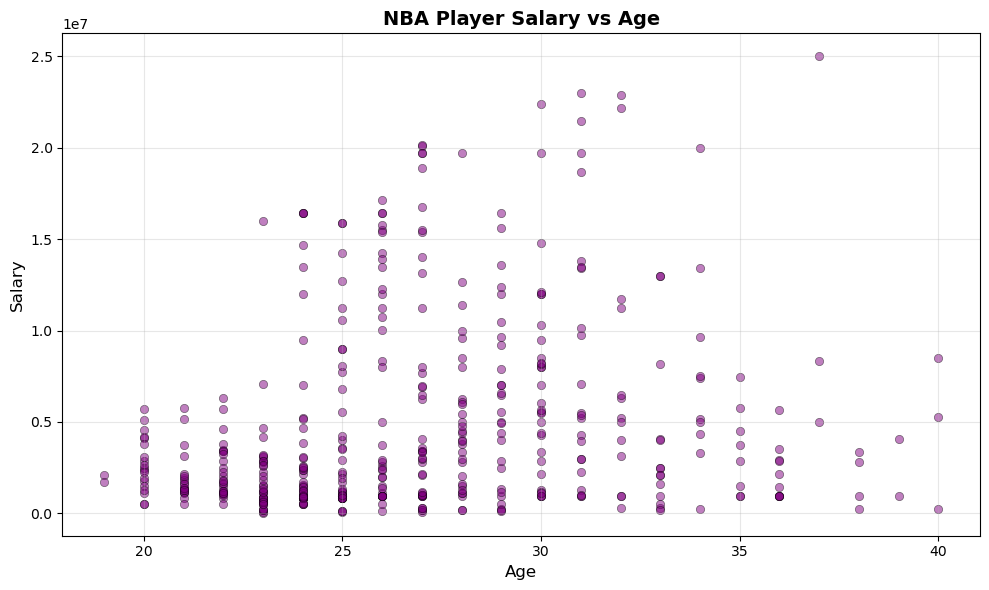

In [60]:
# Step 8 Code Cell
nba.plot_scatter("Age", "Salary", color='purple', alpha=0.5,
                 title='NBA Player Salary vs Age')

In [61]:
# Step 8 Code Cell
print("Median Salary:", nba.get_median("Salary"))
print("Median Age:", nba.get_median("Age"))
print("Median Weight:", nba.get_median("Weight"))

Median Salary: 2839073.0
Median Age: 26.0
Median Weight: 220.0


In [62]:
# Step 8 Code Cell
centers = nba.filter_data("Position", "==", "C")
print(f"Found {centers.n} centers in the dataset")
print(f"\nAverage Center Salary: ${centers.get_mean('Salary'):,.2f}")
print(f"Average Center Weight: {centers.get_mean('Weight'):.1f} lbs")

Found 78 centers in the dataset

Average Center Salary: $5,967,052.00
Average Center Weight: 254.2 lbs


### Phase 2 Submission
To submit to Gradescope, 
1. Hit "Kernel --> Restart & Clear Output"
2. Run, in order, all the above code cells (all from phases 0-1).   Then save this notebook.  Be sure that all output works (e.g. that you pass the provided tests, that your output from steps 7-8 is shown, etc).
3. Create a PDF of your notebook.  To do so, (1) hit File -> Download as -> HTML, (2) open that HTML file in Google Chrome (I drag from downloads into a new Chrome tab), and (3) save that HTML file as a PDF (I type `ctrl+P` to print and then select `Save as PDF` as my destination).  Note that this is a bit more involved than just saving as a PDF directly from Jupyter, but usually leads to better-formatted notebooks so **please follow this process exactly.**
4. Create a `.zip` folder including everything in the Project 1 directory (including all of the original files and csvs + any additional csvs you used in steps 7-8 + your PDF).
5. Uplad that `.zip` folder to Gradescope.

**Note** Parts of Gradescope are a bit finnicky when it comes to Jupyter notebooks.  You MUST follow the above instructions exactly: if I cannot grade a submission through Gradescope, it will get 0 points.  Please let me know ahead of time if you have any submission issues or are unsure of what to do.